In [ ]:
!wget -O dataset.zip \
"https://huggingface.co/datasets/harvardairobotics/Harvard-GF/resolve/main/Dataset/dataset.zip"


--2026-10-25 21:32:16--  https://huggingface.co/datasets/harvardairobotics/Harvard-GF/resolve/main/Dataset/dataset.zip
Resolving huggingface.co (huggingface.co)... 13.35.202.34, 13.35.202.121, 13.35.202.97, ...
Connecting to huggingface.co (huggingface.co)|13.35.202.34|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/69d5c8f314dc8a2c4744c046/18880eb8fe52d77be1c7f42e36100a3f4e631b9168b34c06f9f10dd4e6869257?X-Xet-Cas-Uid=public&user_id=public&xip=F5v38Tv1ras&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27dataset.zip%3B+filename%3D%22dataset.zip%22%3B&response-content-type=application%2Fzip&Expires=1792967536&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjlkNWM4ZjMxNGRjOGEyYzQ3NDRjMDQ2LzE4ODgwZWI4ZmU1MmQ3N2JlMWM3ZjQyZTM2MTAwYTNmNGU2MzFiOTE2OGIzNGMwNmY5ZjEwZGQ0ZTY4NjkyNTdcXD9YLVhldC1DYXMtVWlkPXB1YmxpYyZ1c2VyX2lkPXB1YmxpYyZ4aXA9RjV2MzhUdjFyYXMmcmVzcG9uc2UtY29

In [ ]:
!unzip -q dataset.zip -d Harvard-GF

In [ ]:
#!rm -rf Harvard-GF/

In [ ]:
%ls

all.zip      Harvard-GF/        __pycache__/  runs_all.zip    sample_data/
data/        make_figures.py    results/      runs_b/         split.py
dataset.py   predict.py         results.zip   runs_c/         train.py
evaluate.py  preprocess_dev.py  runs/         runs_final/     verify.py
extract.py   preprocess.py      runs_a/       runs_full_val/


In [ ]:
!zip -r all_files.zip . -x "./sample_data/*" "./__pycache__/*" "./Harvard-GF/*" "all_files.zip"
!ls -lh all_files.zip

  adding: .config/ (stored 0%)
  adding: .config/.last_survey_prompt.yaml (stored 0%)
  adding: .config/configurations/ (stored 0%)
  adding: .config/configurations/config_default (deflated 15%)
  adding: .config/.last_update_check.json (deflated 22%)
  adding: .config/active_config (stored 0%)
  adding: .config/logs/ (stored 0%)
  adding: .config/logs/2026.10.21/ (stored 0%)
  adding: .config/logs/2026.10.21/13.27.51.774504.log (deflated 58%)
  adding: .config/logs/2026.10.21/13.28.05.116687.log (deflated 57%)
  adding: .config/logs/2026.10.21/13.27.28.750982.log (deflated 92%)
  adding: .config/logs/2026.10.21/13.28.04.564766.log (deflated 57%)
  adding: .config/logs/2026.10.21/13.27.57.480371.log (deflated 87%)
  adding: .config/logs/2026.10.21/13.27.58.650478.log (deflated 58%)
  adding: .config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db (deflated 97%)
  adding: .config/config_sentinel (stored 0%)
  adding: .config/.last_opt_in_prompt.yaml (stored 0%)
  adding: 

In [ ]:
import os
for s in ["Training", "Validation", "Test"]:
    print(s, len(os.listdir(f"Harvard-GF/{s}")))

Training 2100
Validation 300
Test 900


In [ ]:
# 2. Inspect one file: keys, shapes, dtypes
import numpy as np, glob
files = sorted(glob.glob("Harvard-GF/**/data_*.npz", recursive=True))
print("total files:", len(files), "(expected 3300)")
print(files[0])

with np.load(files[0], allow_pickle=True) as d:
    for k in d.files:
        print(f"{k:15s} shape={d[k].shape}  dtype={d[k].dtype}")

total files: 3300 (expected 3300)
Harvard-GF/Test/data_2401.npz
oct_bscans      shape=(200, 200, 200)  dtype=uint8
rnflt           shape=(200, 200)  dtype=float64
md              shape=()  dtype=float64
glaucoma        shape=()  dtype=int64
tds             shape=(52,)  dtype=float64
race            shape=()  dtype=<U18
male            shape=()  dtype=int64
hispanic        shape=()  dtype=int64
language        shape=()  dtype=int64
maritalstatus   shape=()  dtype=int64
age             shape=()  dtype=float64


In [ ]:
!python extract.py

(3300, 200, 200) {'train': 2100, 'test': 900, 'val': 300}


In [ ]:
!python verify.py

[PASS] file count (files=3300, meta=3300, rnflt=3300)
[PASS] rnflt shape/dtype (3300, 200, 200)
[PASS] row order matches raw files 
[PASS] unique filenames 
[PASS] no NaN/inf in rnflt 
[PASS] no nulls in meta 
[PASS] split sizes {'train': 2100, 'test': 900, 'val': 300}
[PASS] labels binary 
[PASS] race values 
[PASS] race balanced per split 
race   Asian  Black or African American  White or Caucasian
split                                                      
test     300                        300                 300
train    700                        700                 700
val      100                        100                 100
split
test     0.543
train    0.516
val      0.587
[PASS] negative codes only -1/-2 {-2.0, -1.0}
[PASS] no all-invalid maps 
age range: 10.12054794520548 97.95616438356164
[PASS] rnflt identical to raw (all 3300) mismatches=0 []
[PASS] meta identical to raw (all 3300) mismatches=0 []

ALL CHECKS PASSED


In [ ]:
!python split.py

{'dev_train': 1680, 'test': 900, 'dev_val': 420, 'val': 300}


In [ ]:
!python preprocess.py

mu=73.04 sd=40.23 norm shape=(3300, 200, 200)


In [ ]:
import numpy as np, pandas as pd, json
D = "data/processed"
norm = np.load(f"{D}/rnflt_norm.npy"); mask = np.load(f"{D}/rnflt_mask.npy")
meta = pd.read_csv(f"{D}/meta.csv")
print(json.load(open(f"{D}/norm_stats.json")))
print("finite:", np.isfinite(norm).all(), "| shape:", norm.shape)
tr = (meta.dev_split == "dev_train").values
v = norm[tr][mask[tr] > 0]
print("dev_train valid pixels: mean=%.3f std=%.3f (should be ~0 and ~1)" % (v.mean(), v.std()))
print("norm range:", norm.min().round(2), norm.max().round(2))
print("invalid pixels are exactly 0:", bool((norm[mask == 0] == 0).all()))
print(meta.groupby("dev_split")[["glaucoma"]].mean().round(3).T)

{'mu': 73.04469299316406, 'sd': 40.22967529296875, 'clip': 400.0}
finite: True | shape: (3300, 200, 200)
dev_train valid pixels: mean=0.000 std=1.000 (should be ~0 and ~1)
norm range: -1.77 8.13
invalid pixels are exactly 0: True
dev_split  dev_train  dev_val   test    val
glaucoma       0.515    0.517  0.543  0.587


In [ ]:
# !zip -r data.zip data/
# !ls -lh data.zip

  adding: data/ (stored 0%)
  adding: data/processed/ (stored 0%)
  adding: data/processed/norm_stats.json (deflated 8%)
  adding: data/processed/rnflt_norm.npy (deflated 89%)
  adding: data/processed/rnflt_mask.npy (deflated 99%)
  adding: data/processed/rnflt_raw.npy (deflated 89%)
  adding: data/processed/meta.csv (deflated 84%)
-rw-r--r-- 1 root root 117M Oct 25 21:21 data.zip


In [ ]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

True Tesla T4


In [ ]:
!ls *.py data/processed

dataset.py  extract.py	preprocess.py  split.py  train.py  verify.py

data/processed:
meta.csv  norm_stats.json  rnflt_mask.npy  rnflt_norm.npy  rnflt_raw.npy


In [ ]:
!python train.py --epochs 3

ep00 loss=0.6112 val_auroc=0.8135 ece=0.0504
ep01 loss=0.5268 val_auroc=0.8350 ece=0.2650
ep02 loss=0.4617 val_auroc=0.8381 ece=0.0618

best epoch 2: {
 "auroc": 0.8381194524528388,
 "ece": 0.06182261843766486,
 "auroc_Asian": 0.8294430794430795,
 "auroc_Black or African American": 0.8742245989304814,
 "auroc_White or Caucasian": 0.8052825552825553
}


In [ ]:
!python train.py --epochs 30 --aug

ep00 loss=0.6146 val_auroc=0.8104 ece=0.0441
ep01 loss=0.5561 val_auroc=0.8171 ece=0.2035
ep02 loss=0.5414 val_auroc=0.8308 ece=0.2210
ep03 loss=0.5156 val_auroc=0.8029 ece=0.0832
ep04 loss=0.5139 val_auroc=0.8208 ece=0.0709
ep05 loss=0.5232 val_auroc=0.8465 ece=0.0653
ep06 loss=0.5219 val_auroc=0.8390 ece=0.0816
ep07 loss=0.4928 val_auroc=0.8345 ece=0.1461
ep08 loss=0.4899 val_auroc=0.8570 ece=0.0533
ep09 loss=0.4723 val_auroc=0.8318 ece=0.2144
ep10 loss=0.4823 val_auroc=0.8413 ece=0.0535
ep11 loss=0.4593 val_auroc=0.8590 ece=0.0703
ep12 loss=0.4524 val_auroc=0.8244 ece=0.1128
ep13 loss=0.4414 val_auroc=0.8036 ece=0.2412
ep14 loss=0.4265 val_auroc=0.8340 ece=0.0792
ep15 loss=0.4162 val_auroc=0.8224 ece=0.1365
ep16 loss=0.4090 val_auroc=0.8300 ece=0.0821
ep17 loss=0.3936 val_auroc=0.8142 ece=0.2167
ep18 loss=0.3688 val_auroc=0.7976 ece=0.1967
ep19 loss=0.3567 val_auroc=0.8089 ece=0.1296
ep20 loss=0.3322 val_auroc=0.8055 ece=0.1342
ep21 loss=0.2948 val_auroc=0.8042 ece=0.1515
ep22 loss=

In [ ]:
!python train.py --epochs 15 --aug --out runs_a

ep00 loss=0.6139 val_auroc=0.8097 ece=0.0533
ep01 loss=0.5564 val_auroc=0.8188 ece=0.2185
ep02 loss=0.5423 val_auroc=0.8313 ece=0.2091
ep03 loss=0.5160 val_auroc=0.7908 ece=0.1687
ep04 loss=0.5112 val_auroc=0.8286 ece=0.0506
ep05 loss=0.5180 val_auroc=0.8449 ece=0.0906
ep06 loss=0.5032 val_auroc=0.8473 ece=0.0741
ep07 loss=0.4759 val_auroc=0.8427 ece=0.1556
ep08 loss=0.4715 val_auroc=0.8595 ece=0.0822
ep09 loss=0.4484 val_auroc=0.8479 ece=0.1114
ep10 loss=0.4382 val_auroc=0.8522 ece=0.0654
ep11 loss=0.4237 val_auroc=0.8561 ece=0.0759
ep12 loss=0.4015 val_auroc=0.8425 ece=0.0935
ep13 loss=0.3901 val_auroc=0.8470 ece=0.0654
ep14 loss=0.3723 val_auroc=0.8462 ece=0.0584

best epoch 8: {
 "auroc": 0.8595151074890468,
 "ece": 0.08223985566624574,
 "auroc_Asian": 0.8857493857493857,
 "auroc_Black or African American": 0.8579679144385026,
 "auroc_White or Caucasian": 0.8378378378378379
}


In [ ]:
!python train.py --epochs 15 --aug --pretrained --lr 1e-4 --out runs_b

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 219MB/s]
ep00 loss=0.5852 val_auroc=0.8587 ece=0.1242
ep01 loss=0.4825 val_auroc=0.8535 ece=0.0925
ep02 loss=0.4151 val_auroc=0.8680 ece=0.0873
ep03 loss=0.3266 val_auroc=0.8282 ece=0.1163
ep04 loss=0.2596 val_auroc=0.8437 ece=0.1196
ep05 loss=0.1523 val_auroc=0.8432 ece=0.1287
ep06 loss=0.1146 val_auroc=0.8321 ece=0.1566
ep07 loss=0.0791 val_auroc=0.8442 ece=0.1551
ep08 loss=0.0553 val_auroc=0.8406 ece=0.1710
ep09 loss=0.0345 val_auroc=0.8371 ece=0.1694
ep10 loss=0.0267 val_auroc=0.8383 ece=0.1615
ep11 loss=0.0202 val_auroc=0.8394 ece=0.1484
ep12 loss=0.0157 val_auroc=0.8354 ece=0.1647
ep13 loss=0.0144 val_auroc=0.8362 ece=0.1479
ep14 loss=0.0147 val_auroc=0.8374 ece=0.1517

best epoch 2: {
 "auroc": 0.8679712151824024,
 "ece": 0.08732284172659831,
 "auroc_Asian": 0.8970106470106469,
 "auroc_Black or African American": 0.88

In [ ]:
!python train.py --epochs 15 --aug --pretrained --lr 1e-4 --use_mask --out runs_c

ep00 loss=0.5666 val_auroc=0.8439 ece=0.1152
ep01 loss=0.4916 val_auroc=0.8463 ece=0.0960
ep02 loss=0.4547 val_auroc=0.8413 ece=0.0685
ep03 loss=0.3967 val_auroc=0.8160 ece=0.2333
ep04 loss=0.3249 val_auroc=0.8238 ece=0.1899
ep05 loss=0.2559 val_auroc=0.8255 ece=0.1108
ep06 loss=0.1838 val_auroc=0.8306 ece=0.1802
ep07 loss=0.1260 val_auroc=0.8341 ece=0.1320
ep08 loss=0.0710 val_auroc=0.8318 ece=0.1629
ep09 loss=0.0484 val_auroc=0.8106 ece=0.1832
ep10 loss=0.0356 val_auroc=0.8289 ece=0.1738
ep11 loss=0.0302 val_auroc=0.8319 ece=0.1705
ep12 loss=0.0224 val_auroc=0.8322 ece=0.1828
ep13 loss=0.0165 val_auroc=0.8337 ece=0.1791
ep14 loss=0.0181 val_auroc=0.8325 ece=0.1706

best epoch 1: {
 "auroc": 0.8463144991033121,
 "ece": 0.09598381182267553,
 "auroc_Asian": 0.88001638001638,
 "auroc_Black or African American": 0.8862032085561498,
 "auroc_White or Caucasian": 0.7794840294840295
}


In [ ]:
%%bash
for s in 0 1 2; do
  python train.py --epochs 15 --aug --seed $s --out runs_a > /dev/null
  python train.py --epochs 6 --aug --pretrained --lr 1e-4 --seed $s --out runs_b > /dev/null
done

In [ ]:
import json, glob, numpy as np
for d in ["runs_a", "runs_b"]:
    m = [json.load(open(f))["metrics"] for f in sorted(glob.glob(f"{d}/*.json"))]
    au = [x["auroc"] for x in m]; ec = [x["ece"] for x in m]
    print(f"{d}: AUROC {np.mean(au):.3f} ± {np.std(au):.3f} | ECE {np.mean(ec):.3f} | seeds={len(m)}")

runs_a: AUROC 0.858 ± 0.003 | ECE 0.086 | seeds=3
runs_b: AUROC 0.849 ± 0.007 | ECE 0.144 | seeds=3


In [ ]:
s = open("train.py").read()

# 1. new flag
old1 = 'p.add_argument("--final"'
new1 = 'p.add_argument("--save_last", action="store_true", help="keep final-epoch weights/probs instead of best-epoch")\np.add_argument("--final"'
assert old1 in s
s = s.replace(old1, new1, 1)

# 2. keep the latest epoch when --save_last is set
old2 = '''    if m["auroc"] > best:
        best, best_ep, best_m, best_p = m["auroc"], ep, m, pr
        torch.save(net.state_dict(), f"{a.out}/{name}.pt")
'''
new2 = '''    if a.save_last:
        best_ep, best_m, best_p = ep, m, pr          # always the latest epoch
    elif m["auroc"] > best:
        best, best_ep, best_m, best_p = m["auroc"], ep, m, pr
        torch.save(net.state_dict(), f"{a.out}/{name}.pt")

if a.save_last:
    torch.save(net.state_dict(), f"{a.out}/{name}.pt")
'''
assert old2 in s
s = s.replace(old2, new2, 1)

# 3. honest label in the final printout
old3 = 'print(f"\\nbest epoch {best_ep}:"'
new3 = 'print(f"\\n{\'final\' if a.save_last else \'best\'} epoch {best_ep}:"'
assert old3 in s
s = s.replace(old3, new3, 1)

open("train.py", "w").write(s)
print("patched")

patched


In [ ]:
%%bash
for s in 0 1 2 3 4; do
  python train.py --epochs 15 --aug --save_last --seed $s --out runs_final | tail -n 8
done


final epoch 14: {
 "auroc": 0.8413656897686771,
 "ece": 0.06250665835326627,
 "auroc_Asian": 0.8669123669123668,
 "auroc_Black or African American": 0.8399999999999999,
 "auroc_White or Caucasian": 0.8251433251433252
}

final epoch 14: {
 "auroc": 0.8491067172141382,
 "ece": 0.08057845571920985,
 "auroc_Asian": 0.8806306306306307,
 "auroc_Black or African American": 0.8382887700534759,
 "auroc_White or Caucasian": 0.829033579033579
}

final epoch 14: {
 "auroc": 0.8420240176159453,
 "ece": 0.08795543126761914,
 "auroc_Asian": 0.8703931203931204,
 "auroc_Black or African American": 0.8408556149732619,
 "auroc_White or Caucasian": 0.8204340704340705
}

final epoch 14: {
 "auroc": 0.8426369435427119,
 "ece": 0.09333024369109245,
 "auroc_Asian": 0.8591318591318591,
 "auroc_Black or African American": 0.84,
 "auroc_White or Caucasian": 0.8314905814905815
}

final epoch 14: {
 "auroc": 0.8525345622119818,
 "ece": 0.06243949408332507,
 "auroc_Asian": 0.8902538902538902,
 "auroc_Black or Afri

In [ ]:
!cp -r runs_final /content/drive/MyDrive/graft_glaucoma/

import json, glob, numpy as np
m = [json.load(open(f))["metrics"] for f in sorted(glob.glob("runs_final/*.json"))]
au = [x["auroc"] for x in m]; ec = [x["ece"] for x in m]
print(f"final-epoch AUROC {np.mean(au):.3f} ± {np.std(au):.3f} | ECE {np.mean(ec):.3f} | seeds={len(m)}")
for i, x in enumerate(m): print(i, round(x["auroc"], 3), round(x["ece"], 3))

cp: cannot create directory '/content/drive/MyDrive/graft_glaucoma/': No such file or directory
final-epoch AUROC 0.846 ± 0.004 | ECE 0.077 | seeds=5
0 0.841 0.063
1 0.849 0.081
2 0.842 0.088
3 0.843 0.093
4 0.853 0.062


In [ ]:
!zip -r all.zip results runs_final runs_full_val
!ls -lh all.zip

  adding: results/ (stored 0%)
  adding: results/runs_full_val/ (stored 0%)
  adding: results/runs_full_val/ensemble_val.json (deflated 51%)
  adding: results/runs_full_val/ensemble_val_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed1_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed2_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed3_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed0_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed4_probs.npy (deflated 10%)
  adding: results/figs/ (stored 0%)
  adding: results/figs/uncertainty_vs_error_test.png (deflated 19%)
  adding: results/figs/uncertainty_vs_error_dev_val.png (deflated 18%)
  adding: results/figs/auroc_by_race_test.png (deflated 15%)
  adding: results/figs/evaluation_dashboard_test.png (deflated 16%)
  adding: results/figs/auroc_by_race_dev_val.png (deflated 16%)
  adding: results/figs/calibration_dev_val.png (deflated 12%)

In [ ]:
!python evaluate.py

5 seeds, 420 patients (dev_val)

PER-SEED (mean ± std)
  auroc                              0.846 ± 0.004
  ece                                0.077 ± 0.013
  auroc_Asian                        0.873 ± 0.011
  auroc_Black or African American    0.840 ± 0.001
  auroc_White or Caucasian           0.826 ± 0.004

ENSEMBLE
  auroc                              0.853   95% CI [0.810, 0.889]
  ece                                0.056
  auroc_Asian                        0.882   95% CI [0.825, 0.934]
  auroc_Black or African American    0.848   95% CI [0.782, 0.908]
  auroc_White or Caucasian           0.828   95% CI [0.744, 0.903]
  worst-to-best race gap: 0.054

UNCERTAINTY  (ensemble accuracy 0.774)
  AUROC of entropy for detecting errors:      0.748
  AUROC of seed disagreement for errors:      0.740
  corr(entropy, disagreement):                0.820

  error rate by entropy quartile:
              mean  size
q                       
Q1 (sure)    0.038   105
Q2           0.181   105
Q3    

saved to results/figs ['uncertainty_vs_error_dev_val.png', 'auroc_by_race_dev_val.png', 'calibration_dev_val.png', 'per_seed_dev_val.png', 'evaluation_dashboard_dev_val.png', 'roc_dev_val.png', 'prob_hist_dev_val.png']


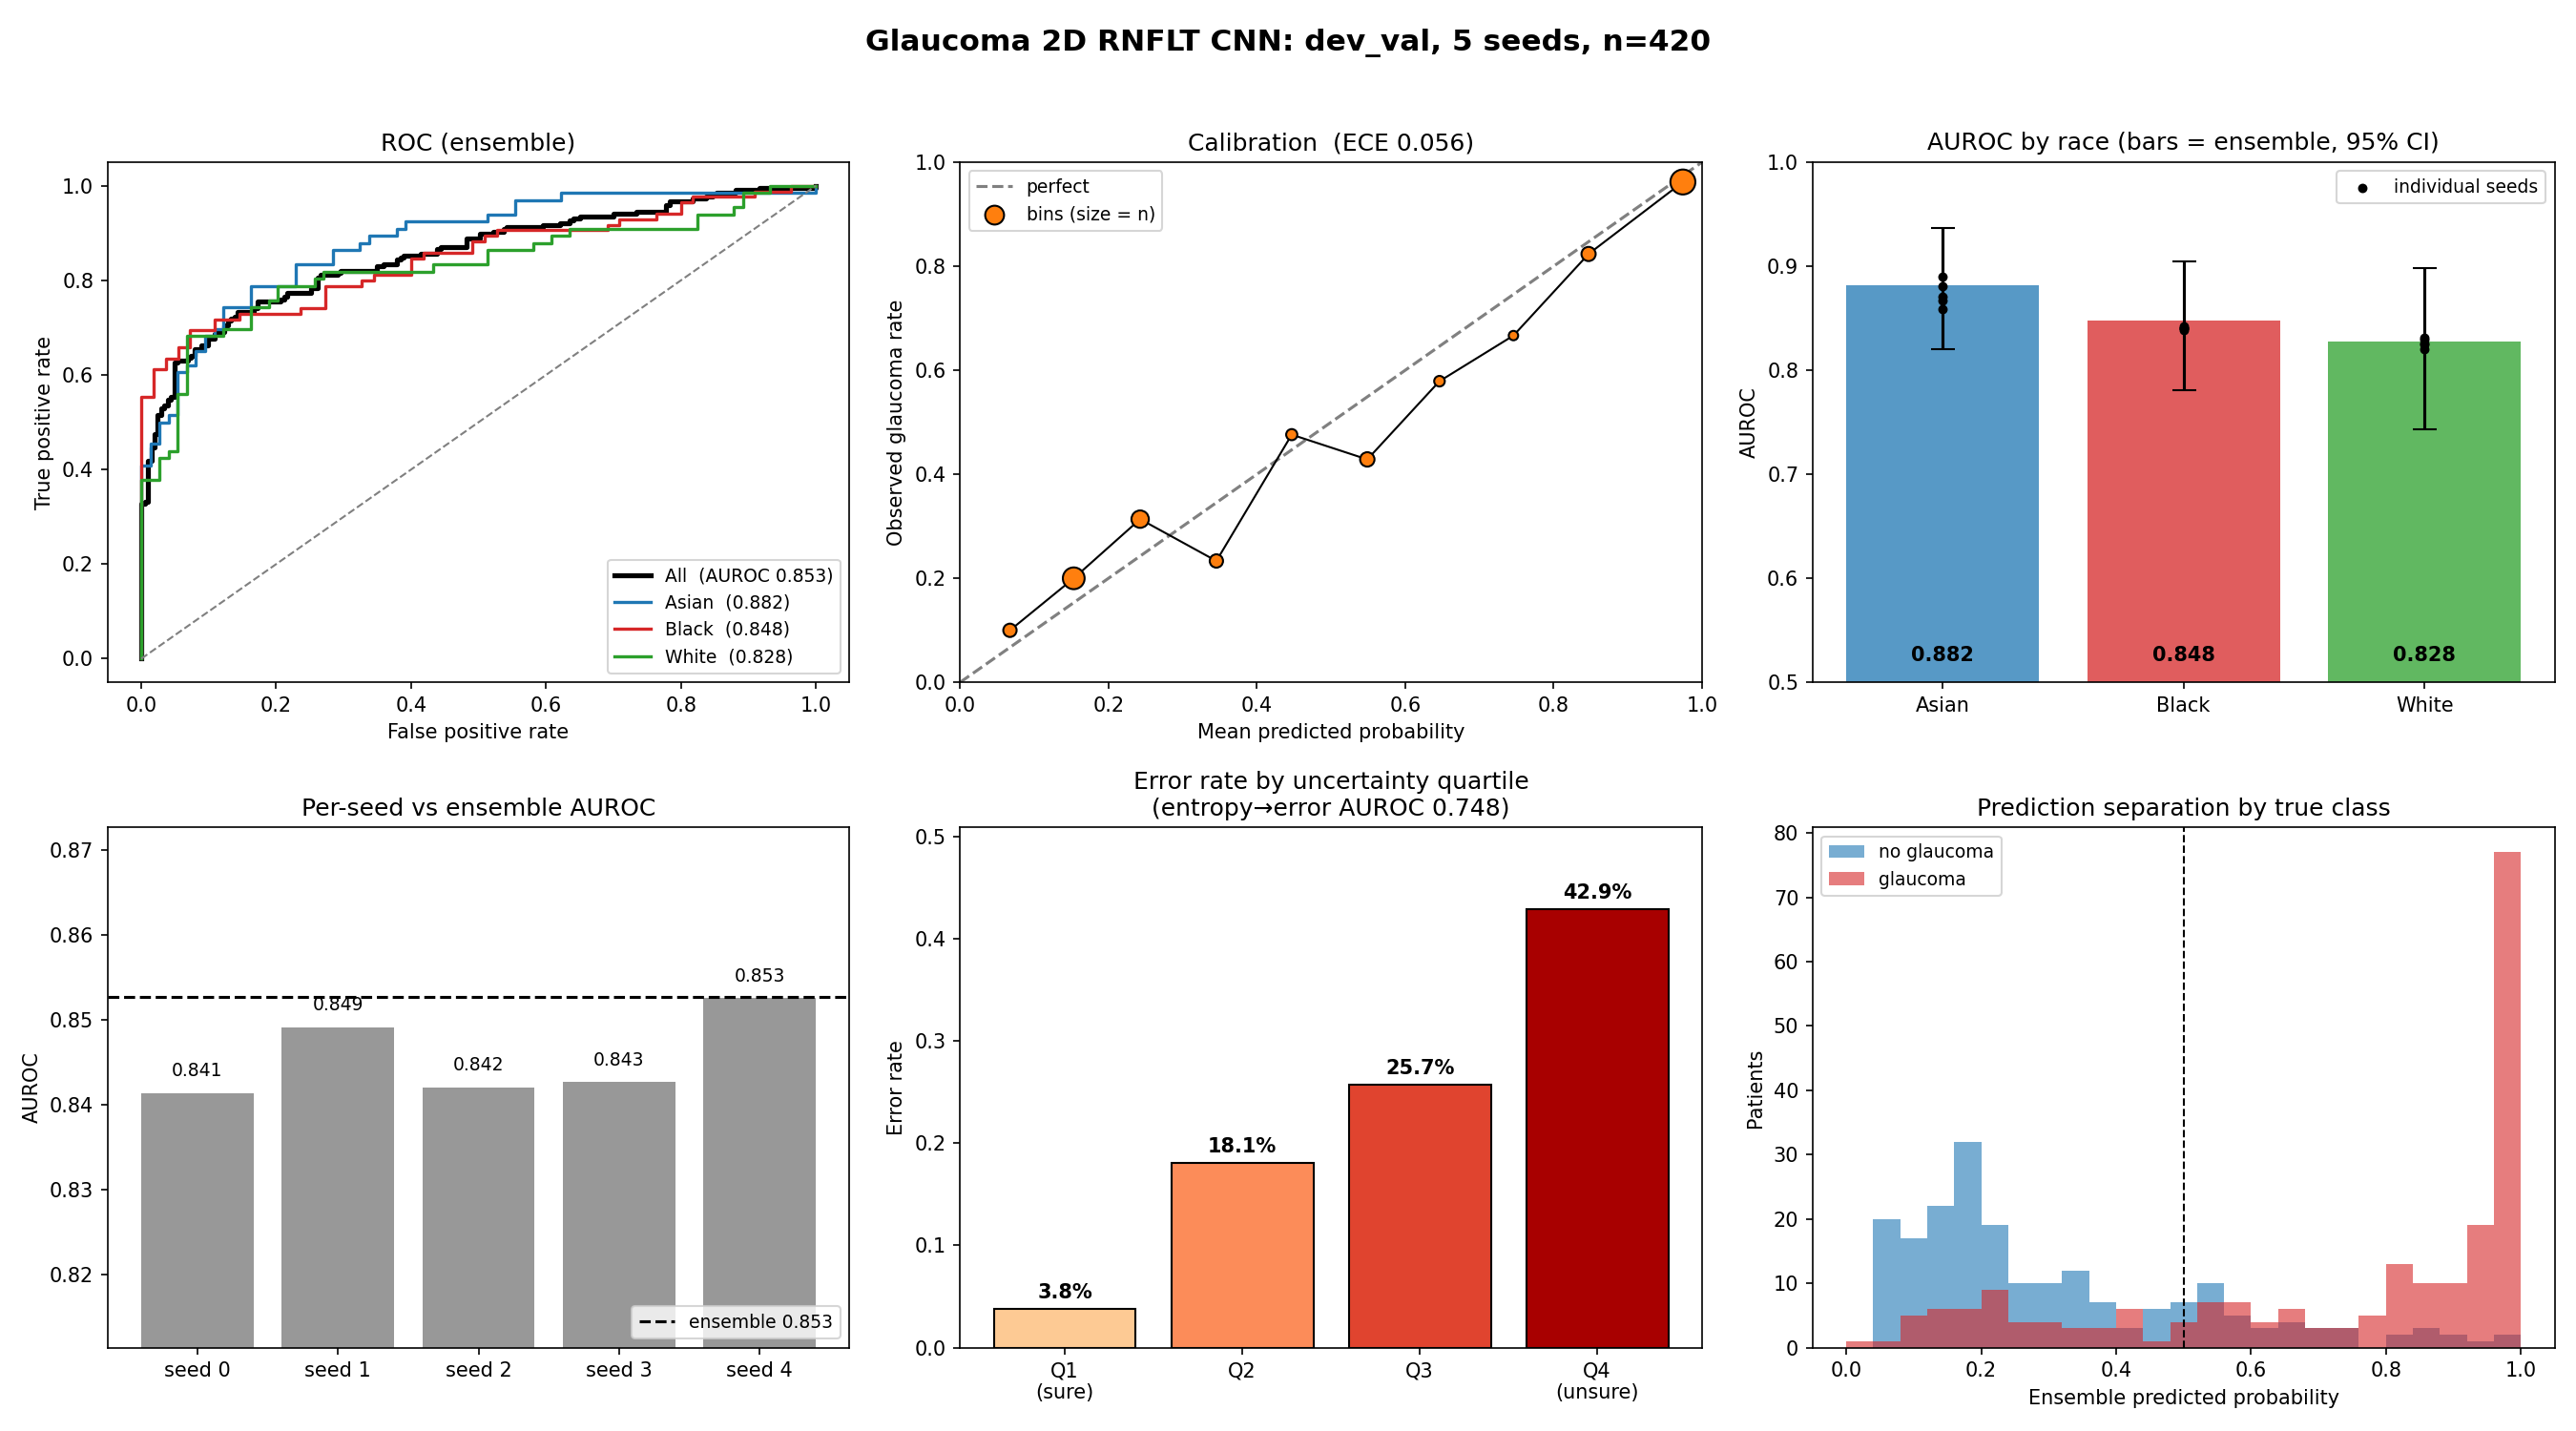

In [ ]:
!python make_figures.py
from IPython.display import Image, display
display(Image("results/figs/evaluation_dashboard_dev_val.png"))

In [ ]:
!zip -r results.zip results
!ls -lh results.zip

  adding: results/ (stored 0%)
  adding: results/runs_full_val/ (stored 0%)
  adding: results/runs_full_val/ensemble_val.json (deflated 51%)
  adding: results/runs_full_val/ensemble_val_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed1_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed2_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed3_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed0_probs.npy (deflated 10%)
  adding: results/runs_full_val/resnet18_seed4_probs.npy (deflated 10%)
  adding: results/figs/ (stored 0%)
  adding: results/figs/uncertainty_vs_error_dev_val.png (deflated 18%)
  adding: results/figs/auroc_by_race_dev_val.png (deflated 16%)
  adding: results/figs/calibration_dev_val.png (deflated 12%)
  adding: results/figs/per_seed_dev_val.png (deflated 22%)
  adding: results/figs/evaluation_dashboard_dev_val.png (deflated 16%)
  adding: results/figs/roc_dev_val.png (deflated 11%)
  adding: re

In [ ]:
!python preprocess.py

fit on split==train (2100 patients): mu=73.10 sd=40.09 shape=(3300, 200, 200)


In [ ]:
import numpy as np, pandas as pd, json
D = "data/processed"
norm = np.load(f"{D}/rnflt_norm.npy"); mask = np.load(f"{D}/rnflt_mask.npy")
meta = pd.read_csv(f"{D}/meta.csv")
print(json.load(open(f"{D}/norm_stats.json")))
tr = (meta.split == "train").values
v = norm[tr][mask[tr] > 0]
print("train valid pixels: mean=%.3f std=%.3f (should be ~0 and ~1)" % (v.mean(), v.std()))
print("finite:", np.isfinite(norm).all(), "| invalid pixels exactly 0:", bool((norm[mask == 0] == 0).all()))

{'mu': 73.09658813476562, 'sd': 40.090877532958984, 'clip': 400.0, 'fit': 'split==train'}
train valid pixels: mean=0.000 std=1.000 (should be ~0 and ~1)
finite: True | invalid pixels exactly 0: True


In [ ]:
%%bash
for s in 0 1 2 3 4; do
  python train.py --epochs 15 --aug --save_last --seed $s \
    --split_col split --train_split train --eval_split val \
    --out results/runs_full | tail -n 8
done


final epoch 14: {
 "auroc": 0.8252382697947215,
 "ece": 0.10032867548366388,
 "auroc_Asian": 0.8169642857142858,
 "auroc_Black or African American": 0.8134642356241233,
 "auroc_White or Caucasian": 0.8303321328531412
}

final epoch 14: {
 "auroc": 0.8301869501466275,
 "ece": 0.10936287487546603,
 "auroc_Asian": 0.8206168831168831,
 "auroc_Black or African American": 0.8214118747078074,
 "auroc_White or Caucasian": 0.8215286114445778
}

final epoch 14: {
 "auroc": 0.8225806451612903,
 "ece": 0.09839162349700926,
 "auroc_Asian": 0.8104707792207791,
 "auroc_Black or African American": 0.8073866292660121,
 "auroc_White or Caucasian": 0.8307322929171669
}

final epoch 14: {
 "auroc": 0.8221682551319647,
 "ece": 0.09104129205147424,
 "auroc_Asian": 0.8137175324675325,
 "auroc_Black or African American": 0.7938288920056101,
 "auroc_White or Caucasian": 0.8391356542617047
}

final epoch 14: {
 "auroc": 0.8299120234604105,
 "ece": 0.08709865803519887,
 "auroc_Asian": 0.8145292207792209,
 "auro

In [ ]:
!python evaluate.py --runs results/runs_full --split_col split --eval_split val

5 seeds, 300 patients (val)

PER-SEED (mean ± std)
  auroc                              0.826 ± 0.003
  ece                                0.097 ± 0.008
  auroc_Asian                        0.815 ± 0.003
  auroc_Black or African American    0.809 ± 0.009
  auroc_White or Caucasian           0.835 ± 0.010

ENSEMBLE
  auroc                              0.832   95% CI [0.780, 0.874]
  ece                                0.077
  auroc_Asian                        0.817   95% CI [0.733, 0.894]
  auroc_Black or African American    0.815   95% CI [0.722, 0.892]
  auroc_White or Caucasian           0.838   95% CI [0.752, 0.917]
  worst-to-best race gap: 0.022

UNCERTAINTY  (ensemble accuracy 0.763)
  AUROC of entropy for detecting errors:      0.710
  AUROC of seed disagreement for errors:      0.706
  corr(entropy, disagreement):                0.822

  error rate by entropy quartile:
              mean  size
q                       
Q1 (sure)    0.013    75
Q2           0.280    75
Q3        

In [ ]:
!python predict.py --runs results/runs_full --split_col split --eval_split val

resnet18_seed0: 300 patients scored
resnet18_seed1: 300 patients scored
resnet18_seed2: 300 patients scored
resnet18_seed3: 300 patients scored
resnet18_seed4: 300 patients scored
saved to results/runs_full_val


In [ ]:
!python evaluate.py --runs results/runs_full_val --split_col split --eval_split val

5 seeds, 300 patients (val)

PER-SEED (mean ± std)
  auroc                              0.826 ± 0.003
  ece                                0.097 ± 0.008
  auroc_Asian                        0.815 ± 0.003
  auroc_Black or African American    0.809 ± 0.009
  auroc_White or Caucasian           0.835 ± 0.010

ENSEMBLE
  auroc                              0.832   95% CI [0.780, 0.874]
  ece                                0.077
  auroc_Asian                        0.817   95% CI [0.733, 0.894]
  auroc_Black or African American    0.815   95% CI [0.722, 0.892]
  auroc_White or Caucasian           0.838   95% CI [0.752, 0.917]
  worst-to-best race gap: 0.022

UNCERTAINTY  (ensemble accuracy 0.763)
  AUROC of entropy for detecting errors:      0.710
  AUROC of seed disagreement for errors:      0.706
  corr(entropy, disagreement):                0.822

  error rate by entropy quartile:
              mean  size
q                       
Q1 (sure)    0.013    75
Q2           0.280    75
Q3        

In [ ]:
!python predict.py --runs results/runs_full --eval_split test --final

resnet18_seed0: 900 patients scored
resnet18_seed1: 900 patients scored
resnet18_seed2: 900 patients scored
resnet18_seed3: 900 patients scored
resnet18_seed4: 900 patients scored
saved to results/runs_full_test


In [ ]:
!python evaluate.py --runs results/runs_full_test --split_col split --eval_split test

5 seeds, 900 patients (test)

PER-SEED (mean ± std)
  auroc                              0.840 ± 0.004
  ece                                0.082 ± 0.013
  auroc_Asian                        0.865 ± 0.004
  auroc_Black or African American    0.792 ± 0.005
  auroc_White or Caucasian           0.844 ± 0.010

ENSEMBLE
  auroc                              0.846   95% CI [0.820, 0.872]
  ece                                0.072
  auroc_Asian                        0.873   95% CI [0.830, 0.912]
  auroc_Black or African American    0.798   95% CI [0.748, 0.851]
  auroc_White or Caucasian           0.851   95% CI [0.806, 0.891]
  worst-to-best race gap: 0.075

UNCERTAINTY  (ensemble accuracy 0.777)
  AUROC of entropy for detecting errors:      0.717
  AUROC of seed disagreement for errors:      0.709
  corr(entropy, disagreement):                0.819

  error rate by entropy quartile:
              mean  size
q                       
Q1 (sure)    0.040   225
Q2           0.191   225
Q3       

saved to results/figs ['uncertainty_vs_error_test.png', 'uncertainty_vs_error_dev_val.png', 'auroc_by_race_test.png', 'evaluation_dashboard_test.png', 'auroc_by_race_dev_val.png', 'calibration_dev_val.png', 'prob_hist_test.png', 'calibration_test.png', 'per_seed_dev_val.png', 'evaluation_dashboard_dev_val.png', 'roc_dev_val.png', 'prob_hist_dev_val.png', 'roc_test.png', 'per_seed_test.png']


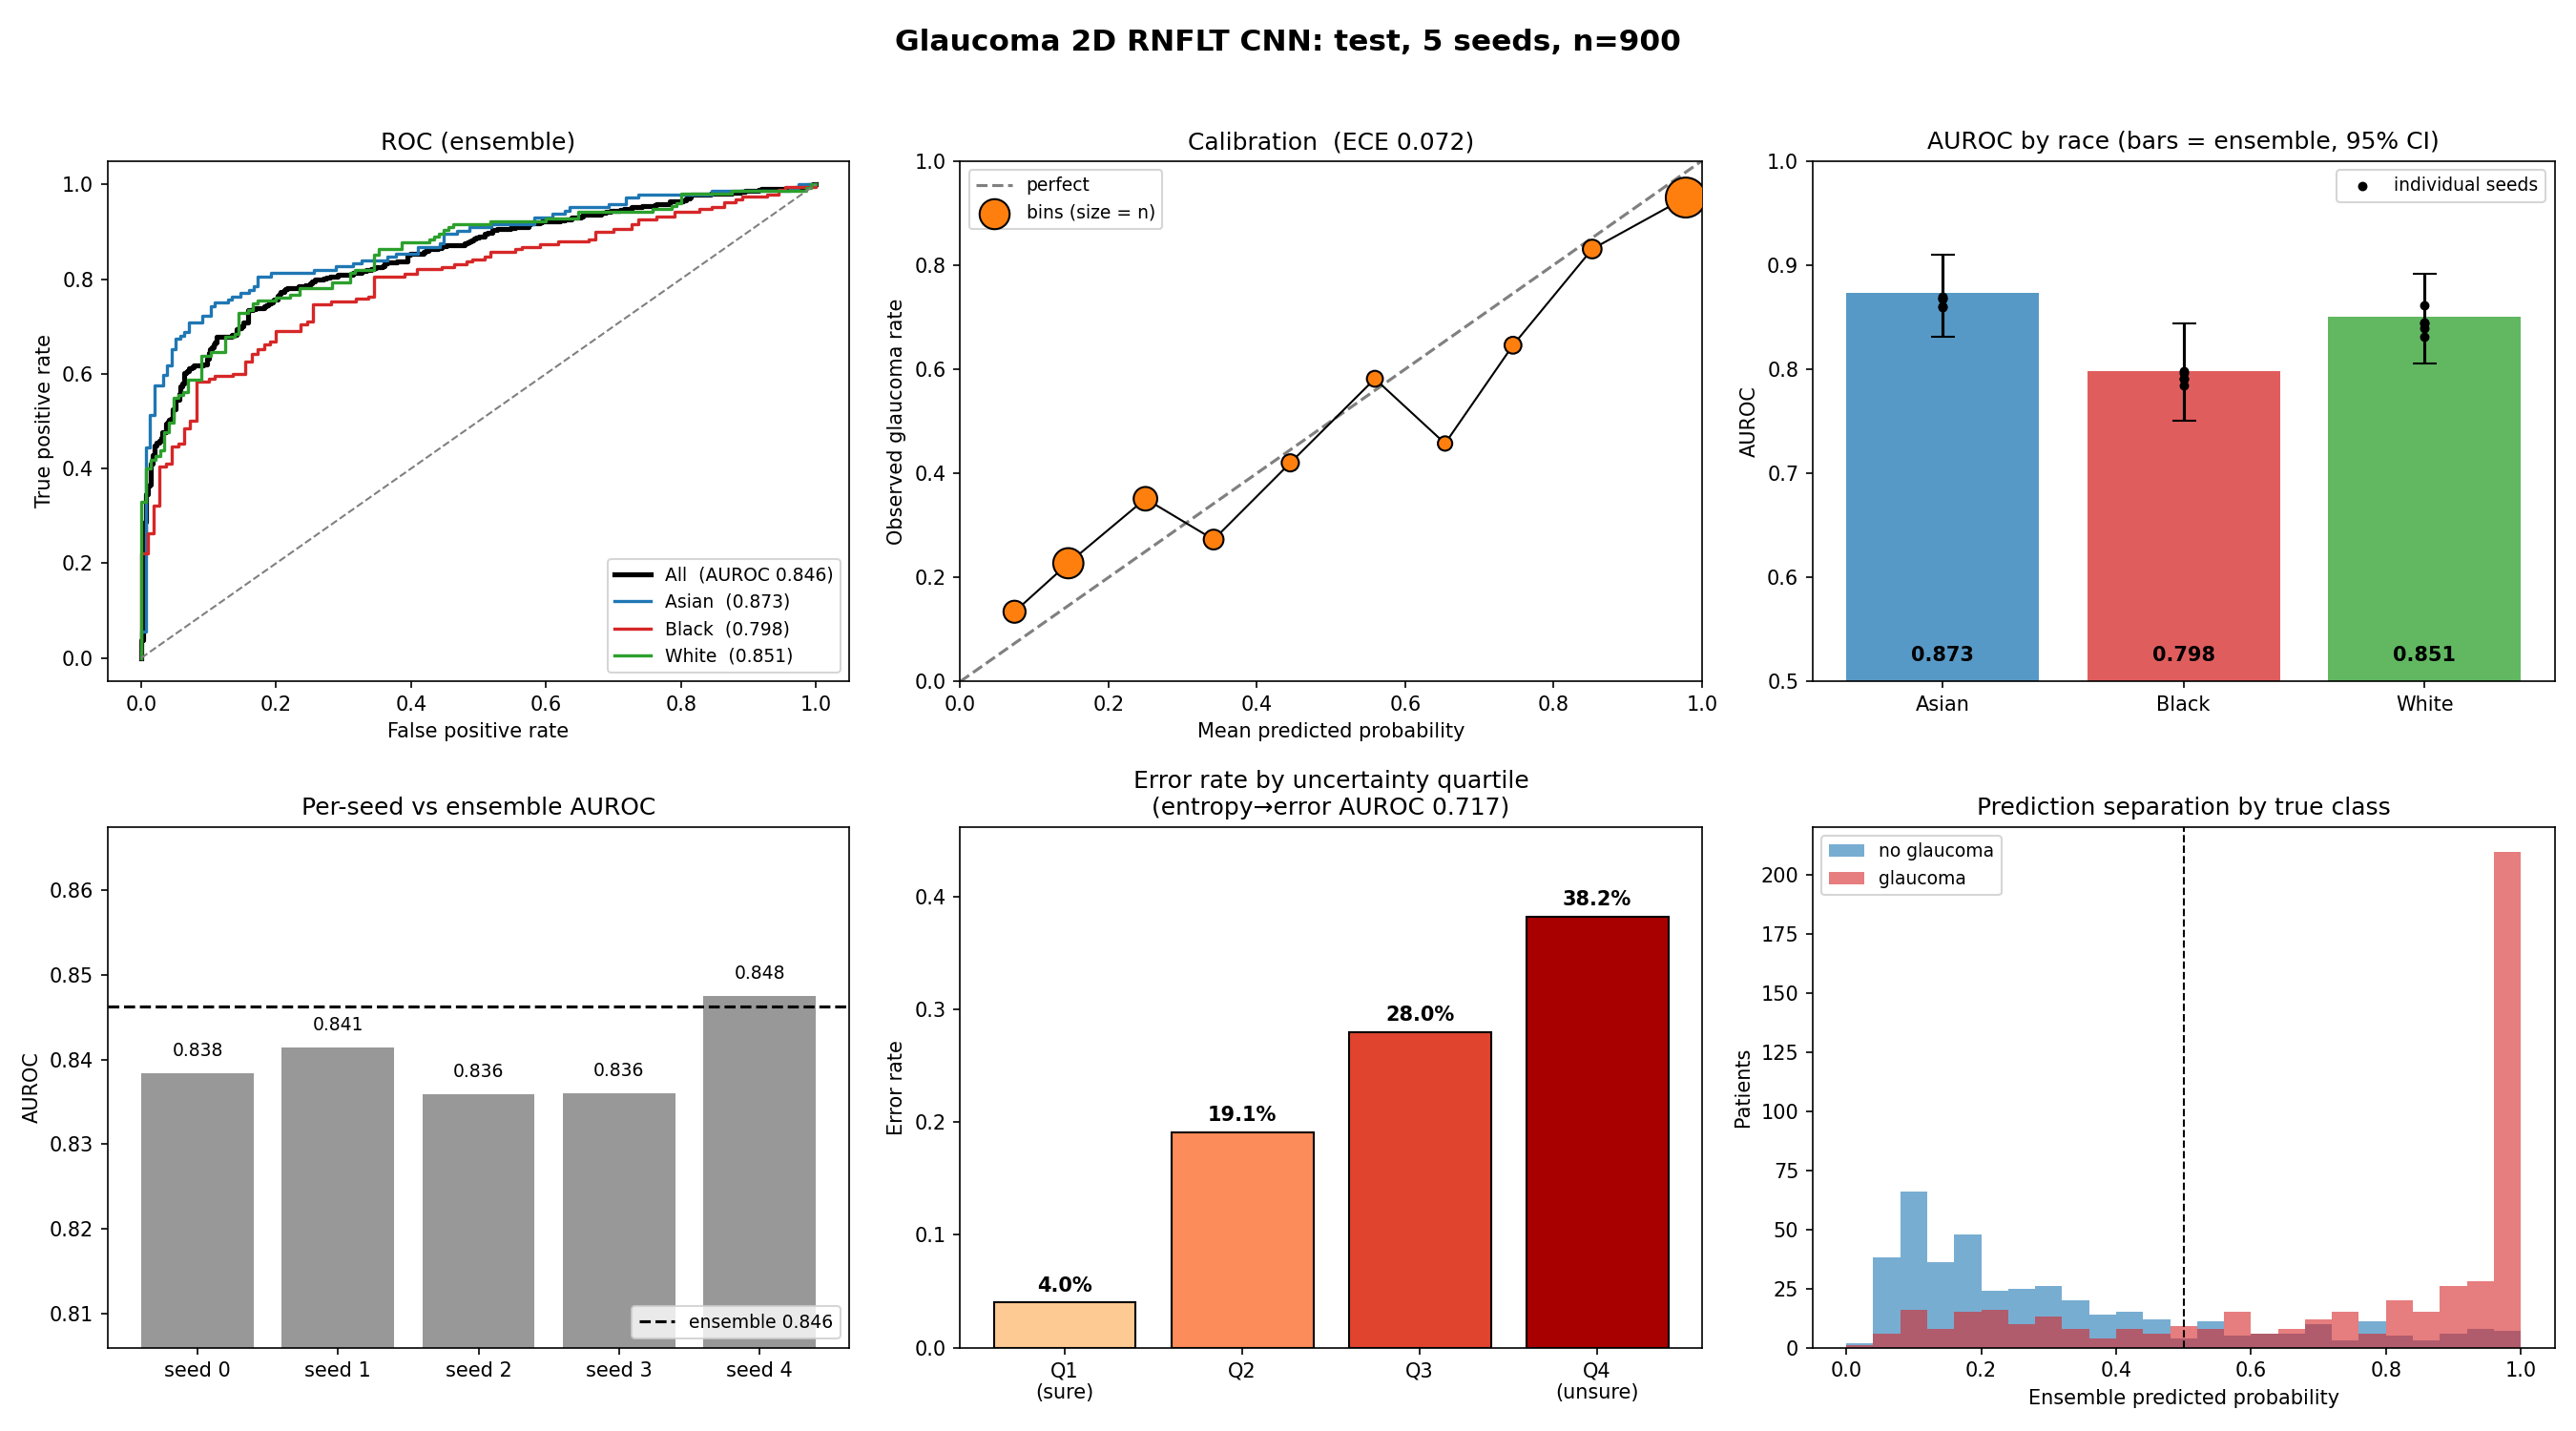

In [ ]:
!python make_figures.py --runs results/runs_full_test --split_col split --eval_split test
from IPython.display import Image, display
display(Image("results/figs/evaluation_dashboard_test.png"))

In [ ]:
!find Harvard-GF -name "*.npz" | head

import glob
import numpy as np

files = glob.glob("Harvard-GF/**/*.npz", recursive=True)

print(f"Found {len(files)} NPZ files")
print(files[:5])

file = files[0]

data = np.load(file)

print("File:", file)
print("Keys:", data.files)

files = glob.glob("Harvard-GF/**/*.npz", recursive=True)
print(len(files))

for key in data.files:
    value = data[key]
    print(f"{key:15} | shape: {value.shape} | dtype: {value.dtype}")
